# Chapter 6: Piotroski F-Score
Use the same public 50-company financial dataset as Chapters 2–5. Run cells in order with **Runtime → Run all** in Google Colab. No credentials, uploads, or private files are needed. The working code is supplied so you can focus on understanding each measure.

Plan: load and inspect (10 minutes), prepare annual comparisons (15), interpret nine signals (25), audit missing fields (10), compare companies (15). A higher score means more favorable financial signals; it is not a return forecast or a recommendation.

This notebook implements the **classroom net-issuance F-Score**. It records the research-definition differences below and never substitutes FS_SCORE, the distinct ten-signal adaptation.


## 1. Load the established dataset
The raw GitHub link is public and stable. It contains saved annual statements, not a live feed. Keep every year in `full_history_df`: current and previous ROA and turnover need **three consecutive balance-sheet dates**. Prices are unnecessary for this accounting score. Each firm's statement values must share one reporting currency and unit; ratios compare like units within that firm.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_URL = 'https://raw.githubusercontent.com/x2003xuy/acct3343-public/main/data/acct3343_financial_data_50.csv'
df = pd.read_csv(DATA_URL)
full_history_df = df.copy(deep=True)
print(f"{len(df)} annual rows; {df['ticker'].nunique()} companies")
display(df[['ticker', 'company_name', 'fiscal_period_end', 'currency']].head())


Matplotlib is building the font cache; this may take a moment.


248 annual rows; 50 companies


,ticker,company_name,fiscal_period_end,currency
0,AAPL,Apple Inc.,2025-09-30,USD
1,AAPL,Apple Inc.,2024-09-30,USD
2,AAPL,Apple Inc.,2023-09-30,USD
3,AAPL,Apple Inc.,2022-09-30,USD
4,AAPL,Apple Inc.,2021-09-30,USD


## 2. The nine tests

| Signal | Measure and comparison | One point when |
|---|---|---|
| F_ROA | Net income / beginning assets | ROA > 0 |
| F_CFO | Operating cash flow / beginning assets | CFO > 0 |
| F_DROA | Current ROA − prior ROA | Change > 0 |
| F_ACCRUAL | CFO versus ROA, both using beginning assets | CFO > ROA |
| F_DLEV | Current long-term debt / ending assets minus prior ratio | Change < 0 |
| F_DLIQ | Current assets / current liabilities, current minus prior | Change > 0 |
| F_EQ | Net common-stock issuance in the current fiscal year | Net proceeds ≤ 0 |
| F_DGM | (Revenue − COGS) / Revenue, current minus prior | Change > 0 |
| F_DAT | Revenue / beginning assets, current minus prior | Change > 0 |

Strict comparisons mean unchanged ROA, leverage, liquidity, margin, or turnover earns **zero**, provided both values are known. Missing information earns **no indicator**. CFO and ROA must be scaled identically before comparing them. Gross profit dollars must be divided by sales to obtain gross margin; do not divide a margin percentage by sales again.

**Equity data:** use `net_common_stock_issuance`, never a change in share count. Splits, stock compensation, conversions, and acquisitions can change shares without equivalent cash issuance. A fallback requires both known nonnegative `issuance_of_capital_stock` and known nonpositive signed `repurchase_of_capital_stock`; their sum is a broader-stock proxy, labeled in `Equity_Source`. Missing proceeds are not assumed zero. Net repurchases may offset gross issuance in this classroom treatment.

**Research distinction:** Piotroski's original paper uses income before extraordinary items, average assets for leverage and turnover, long-term debt including its current portion, and a no-equity-offer indicator. Our class uses saved `net_income`, ending assets for leverage, beginning assets for turnover, saved noncurrent `long_term_debt`, and net issuance. The CSV cannot identify the current portion of long-term debt separately or fully distinguish issuance events. Thus this is a transparent classroom implementation, not an exact reconstruction of the original research variable. [Piotroski (2000), definitions and Table 1](https://www.rentables.fr/wp-content/uploads/2011/01/Piotroski_Value-Investing.pdf).

**Classroom corrections:** the improvement threshold is ΔROA > 0. Positive change need not exceed 1. The displayed CFO division should be approximately 11.23%, rather than 1.12%. Both corrections preserve the intended indicator directions. The classroom prior sales inputs differ across margin and turnover calculations; use consistent actual annual records for company analysis.


## 3. Prepare annual data and calculate
The helpers below convert fields to numbers, reject infinities, preserve missing values, sort within each ticker, and require consecutive integer fiscal years with 350–380 days between dates. Duplicate or invalid dates flag the whole company's score for review. `.shift()` retrieves the previous row **within the same company**. The code does not backfill a missing year or switch to an older complete score.

Read `calculate_fscore` alongside the table above. `indicator` converts a known true/false test to 1/0 while retaining `<NA>` for an unknown comparison. `ratio` withholds division by zero or nonpositive assets or liabilities.


In [2]:
"""Canonical Chapter 6 classroom F-Score; unavailable signals remain missing."""
import numpy as np
import pandas as pd

SIGNALS = ['F_ROA', 'F_CFO', 'F_DROA', 'F_ACCRUAL', 'F_DLEV', 'F_DLIQ', 'F_EQ', 'F_DGM', 'F_DAT']
FIELDS = ['net_income', 'operating_cash_flow', 'total_assets', 'long_term_debt',
          'current_assets', 'current_liabilities', 'total_revenue', 'cost_of_revenue',
          'net_common_stock_issuance', 'issuance_of_capital_stock', 'repurchase_of_capital_stock']

def ratio(numerator, denominator):
    """Only finite numerators and strictly positive finite denominators qualify."""
    return numerator.where(np.isfinite(numerator)) / denominator.where(np.isfinite(denominator) & denominator.gt(0))

def indicator(left, right=0, direction='greater'):
    """Nullable integer avoids treating missing comparisons as failed tests."""
    other = right if isinstance(right, pd.Series) else pd.Series(right, index=left.index)
    valid = np.isfinite(left) & np.isfinite(other)
    condition = left.gt(other) if direction == 'greater' else left.lt(other)
    return condition.where(valid).astype('Int64')

def prepare_history(raw):
    df = raw.copy()
    df['fiscal_period_end'] = pd.to_datetime(df['fiscal_period_end'], errors='coerce')
    for field in FIELDS + ['fiscal_year']:
        df[field] = pd.to_numeric(df[field], errors='coerce').replace([np.inf, -np.inf], np.nan) if field in df else np.nan
    return df.sort_values(['ticker', 'fiscal_period_end'], na_position='last').reset_index(drop=True)

def calculate_fscore(raw):
    df = prepare_history(raw)
    grouped = df.groupby('ticker', sort=False)
    previous_date = grouped['fiscal_period_end'].shift()
    days = (df['fiscal_period_end'] - previous_date).dt.days
    year_difference = grouped['fiscal_year'].diff()
    pair_ok = days.between(350, 380) & year_difference.eq(1)
    duplicate = df.duplicated(['ticker', 'fiscal_period_end'], keep=False)
    bad_company = (df['fiscal_period_end'].isna() | duplicate | df['fiscal_year'].mod(1).ne(0)).groupby(df['ticker']).transform('any')
    pair_ok &= ~bad_company
    df['Beginning_Assets'] = grouped['total_assets'].shift().where(pair_ok)
    df['ROA'] = ratio(df['net_income'], df['Beginning_Assets'])
    df['CFO'] = ratio(df['operating_cash_flow'], df['Beginning_Assets'])
    df['Leverage'] = ratio(df['long_term_debt'].where(df['long_term_debt'].ge(0)), df['total_assets'])
    df['Liquidity'] = ratio(df['current_assets'].where(df['current_assets'].ge(0)), df['current_liabilities'])
    df['Gross_Margin'] = ratio(df['total_revenue'] - df['cost_of_revenue'], df['total_revenue'])
    df['Asset_Turnover'] = ratio(df['total_revenue'].where(df['total_revenue'].ge(0)), df['Beginning_Assets'])
    for name in ['ROA', 'Leverage', 'Liquidity', 'Gross_Margin', 'Asset_Turnover']:
        df['Previous_' + name] = df.groupby('ticker')[name].shift().where(pair_ok)
        df['Change_' + name] = df[name] - df['Previous_' + name]
    df['Net_Equity_Issuance'] = df['net_common_stock_issuance']
    df['Equity_Source'] = np.where(df['Net_Equity_Issuance'].notna(), 'net_common_stock_issuance', 'Unavailable')
    # Yahoo cash-flow repurchases are signed cash outflows. Do not infer missing issuance as zero.
    fallback = df['Net_Equity_Issuance'].isna() & df['issuance_of_capital_stock'].ge(0) & df['repurchase_of_capital_stock'].le(0)
    df.loc[fallback, 'Net_Equity_Issuance'] = df.loc[fallback, 'issuance_of_capital_stock'] + df.loc[fallback, 'repurchase_of_capital_stock']
    df.loc[fallback, 'Equity_Source'] = 'capital stock proceeds + signed repurchases (broader stock proxy)'
    df['F_ROA'] = indicator(df['ROA'])
    df['F_CFO'] = indicator(df['CFO'])
    df['F_DROA'] = indicator(df['Change_ROA'])
    df['F_ACCRUAL'] = indicator(df['CFO'], df['ROA'])
    df['F_DLEV'] = indicator(df['Change_Leverage'], direction='less')
    df['F_DLIQ'] = indicator(df['Change_Liquidity'])
    df['F_EQ'] = df['Net_Equity_Issuance'].le(0).where(df['Net_Equity_Issuance'].notna()).astype('Int64')
    df['F_DGM'] = indicator(df['Change_Gross_Margin'])
    df['F_DAT'] = indicator(df['Change_Asset_Turnover'])
    # A company with ambiguous dates must not receive any apparently reliable score.
    df.loc[bad_company, SIGNALS] = pd.NA
    df['Available_Signals'] = df[SIGNALS].count(axis=1)
    df['F_Score'] = df[SIGNALS].sum(axis=1, min_count=9).astype('Int64')
    df['Score_Lower_Bound'] = df[SIGNALS].sum(axis=1, min_count=0).astype('Int64')
    df['Score_Upper_Bound'] = df['Score_Lower_Bound'] + 9 - df['Available_Signals']
    df['Missing_Signals'] = df[SIGNALS].isna().apply(lambda row: ', '.join(row.index[row]), axis=1)
    df['History_Status'] = np.where(bad_company, 'Invalid/duplicate date or fiscal-year label', np.where(pair_ok, 'Consecutive annual pair', 'No consecutive prior year'))
    # Keep the actual latest observation; do not select an older complete score instead.
    latest = df.groupby('ticker', sort=True).tail(1).copy()
    latest['Weak_to_Strong_Rank'] = latest['F_Score'].rank(method='min', ascending=True).astype('Int64')
    return df, latest.sort_values(['F_Score', 'ticker'], na_position='last')


In [3]:
history_df, master_df = calculate_fscore(full_history_df)
final_results = master_df.copy()
display(final_results[['ticker', 'company_name', 'fiscal_period_end', 'History_Status', 'Beginning_Assets', 'ROA', 'CFO', 'Change_ROA']])


,ticker,company_name,fiscal_period_end,History_Status,Beginning_Assets,ROA,CFO,Change_ROA
82,EOG,"EOG Resources, Inc.",2025-12-31,Consecutive annual pair,4.718600e+10,0.105540,0.212860,-0.040457
97,HD,"The Home Depot, Inc.",2026-01-31,Consecutive annual pair,9.611900e+10,0.147276,0.169842,-0.046191
102,HON,Honeywell International Inc.,2025-12-31,Consecutive annual pair,7.519600e+10,0.062889,0.085217,-0.029838
112,JNJ,Johnson & Johnson,2025-12-31,Consecutive annual pair,1.801040e+11,0.148825,0.136199,0.064878
142,MRK,"Merck & Co., Inc.",2025-12-31,Consecutive annual pair,1.171060e+11,0.155876,0.140659,-0.004583
167,NVDA,NVIDIA Corporation,2026-01-31,Consecutive annual pair,1.116010e+11,1.075860,0.920404,-0.032953
197,SBUX,Starbucks Corporation,2025-09-30,Consecutive annual pair,3.133930e+10,0.059236,0.151487,-0.068489
207,SO,The Southern Company,2025-12-31,Consecutive annual pair,1.451800e+11,0.029901,0.067516,-0.001686
38,BLK,"BlackRock, Inc.",2025-12-31,Consecutive annual pair,1.386150e+11,0.040061,0.028330,-0.011631
72,DE,Deere & Company,2025-10-31,Consecutive annual pair,1.073200e+11,0.046841,0.069502,-0.021371


## 4. Inspect funding, liquidity, and efficiency
Negative leverage change and positive liquidity change are favorable. Inspect equity proceeds and their source before accepting the net-issuance point. Missing `Net_Equity_Issuance` stays unknown. A negative gross margin is a valid economic observation; its year-to-year improvement can still pass the margin test.

**Kai prompts:** “Chapter 6: why does leverage need a less-than test?” or “Chapter 6: help me inspect missing equity issuance.”


In [4]:
display(final_results[['ticker', 'Leverage', 'Change_Leverage', 'Liquidity', 'Change_Liquidity', 'Net_Equity_Issuance', 'Equity_Source', 'Gross_Margin', 'Change_Gross_Margin', 'Asset_Turnover', 'Change_Asset_Turnover']])


,ticker,Leverage,Change_Leverage,Liquidity,Change_Liquidity,Net_Equity_Issuance,Equity_Source,Gross_Margin,Change_Gross_Margin,Asset_Turnover,Change_Asset_Turnover
82,EOG,0.150949,0.064016,1.632061,-0.465436,-2.564000e+09,net_common_stock_issuance,0.633779,-0.049598,0.478574,-0.054476
97,HD,0.440944,-0.063483,1.060665,-0.044775,3.140000e+08,net_common_stock_issuance,0.333155,-0.001035,1.713324,-0.371009
102,HON,0.368358,0.030042,1.297813,-0.015134,-3.567000e+09,net_common_stock_issuance,0.369345,-0.015395,0.497925,-0.066349
112,JNJ,0.197972,0.027787,1.027676,-0.083053,-5.953000e+09,net_common_stock_issuance,0.678787,-0.011928,0.522992,-0.007099
142,MRK,0.341575,0.047295,1.536202,0.171600,-5.084000e+09,net_common_stock_issuance,0.748012,-0.015219,0.555147,-0.046381
167,NVDA,0.036116,-0.039716,3.905264,-0.534588,-4.008600e+10,net_common_stock_issuance,0.710681,-0.039206,1.934911,-0.050499
197,SBUX,0.455217,-0.001702,0.723018,-0.031933,7.700000e+07,net_common_stock_issuance,0.227711,-0.040673,1.186510,-0.042071
207,SO,0.421584,0.016790,0.646435,-0.022232,1.623000e+09,net_common_stock_issuance,0.484689,-0.015349,0.203561,0.011759
38,BLK,0.075107,-0.013729,15.760920,-0.589341,-1.951000e+09,net_common_stock_issuance,0.467047,-0.027196,0.174700,0.009073
72,DE,0.410808,0.008003,2.307872,0.148056,-1.138000e+09,net_common_stock_issuance,0.364827,-0.021075,0.416185,-0.069159


## 5. Sum only complete scores and rank weakest to strongest
`.sum(axis=1, min_count=9)` requires all nine known indicators. It prevents pandas from silently treating missing indicators as zero. The lower and upper bounds summarize uncertainty; neither is the final F-Score. For example, six passes and two unknown signals imply a possible score from 6 to 8. Ties share the minimum rank. Incomplete firms remain visible after the ranked firms.


In [5]:
display(final_results[['ticker', *SIGNALS, 'Available_Signals', 'F_Score', 'Score_Lower_Bound', 'Score_Upper_Bound', 'Weak_to_Strong_Rank', 'Missing_Signals']])
eligible = final_results['F_Score'].dropna().astype(int)
print(f"Complete scores: {len(eligible)} / {len(final_results)} companies")
display(eligible.describe())
display(final_results.loc[final_results['F_Score'].isna(), ['ticker', 'History_Status', 'Missing_Signals']])


,ticker,F_ROA,F_CFO,F_DROA,F_ACCRUAL,F_DLEV,F_DLIQ,F_EQ,F_DGM,F_DAT,Available_Signals,F_Score,Score_Lower_Bound,Score_Upper_Bound,Weak_to_Strong_Rank,Missing_Signals
82,EOG,1,1,0,1,0,0,1,0,0,9,4,4,4,1,
97,HD,1,1,0,1,1,0,0,0,0,9,4,4,4,1,
102,HON,1,1,0,1,0,0,1,0,0,9,4,4,4,1,
112,JNJ,1,1,1,0,0,0,1,0,0,9,4,4,4,1,
142,MRK,1,1,0,0,0,1,1,0,0,9,4,4,4,1,
167,NVDA,1,1,0,0,1,0,1,0,0,9,4,4,4,1,
197,SBUX,1,1,0,1,1,0,0,0,0,9,4,4,4,1,
207,SO,1,1,0,1,0,0,0,0,1,9,4,4,4,1,
38,BLK,1,1,0,0,1,0,1,0,1,9,5,5,5,9,
72,DE,1,1,0,1,0,1,1,0,0,9,5,5,5,9,


Complete scores: 43 / 50 companies


count    43.000000
mean      6.232558
std       1.493433
min       4.000000
25%       5.000000
50%       6.000000
75%       7.000000
max       9.000000
Name: F_Score, dtype: float64

,ticker,History_Status,Missing_Signals
29,AMZN,Consecutive annual pair,F_EQ
34,BAC,Consecutive annual pair,"F_DLIQ, F_DGM"
92,GS,Consecutive annual pair,"F_DLIQ, F_DGM"
117,JPM,Consecutive annual pair,"F_DLIQ, F_DGM"
147,MS,Consecutive annual pair,"F_DLIQ, F_DGM"
182,PFE,Consecutive annual pair,F_EQ
237,WFC,Consecutive annual pair,"F_DLIQ, F_DGM"


## 6. Distribution and sector comparisons
Only complete scores enter these summaries. Small groups and missing fields can change apparent sector differences. The dataset is a selected classroom sample; these summaries describe it rather than a representative market universe.


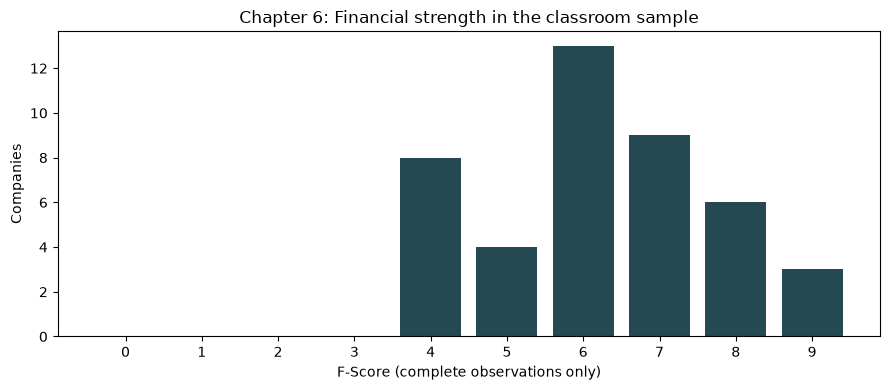

,count,mean,median,min,max
sector,,,,,
Consumer Cyclical,6,6.166667,6.5,4,8
Consumer Defensive,6,7.166667,7.0,6,9
Energy,5,5.2,5.0,4,6
Financial Services,1,5.0,5.0,5,5
Healthcare,6,5.833333,6.0,4,8
Industrials,7,6.571429,6.0,4,9
Technology,8,6.625,7.0,4,8
Utilities,4,5.75,6.0,4,7


In [6]:
distribution = eligible.value_counts().reindex(range(10), fill_value=0).sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(distribution.index, distribution.values, color='#254953')
ax.set(xlabel='F-Score (complete observations only)', ylabel='Companies', title='Chapter 6: Financial strength in the classroom sample', xticks=range(10))
plt.tight_layout()
plt.show()
display(final_results.groupby('sector', dropna=False)['F_Score'].agg(['count', 'mean', 'median', 'min', 'max']))


## 7. Check your understanding
Pick a company and explain one passed test and one failed or unavailable test. Why can two firms have the same score but different risks? Which data would resolve an unknown equity-issuance signal? Ask Kai for one coding step at a time and paste the exact line and error when debugging.

The results use the latest saved fiscal year for each firm, so the dates can differ across companies. A current fundamental ranking cannot establish investment performance or a historical trading strategy.
